1. LOAD

In [1]:
import pandas as pd
import numpy as np

URL = "/content/sensor_readings_export.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(19828, 9)


,reading_id,node_id,timestamp,water_level_cm,flow_rate_lpm,mq4_voltage,mq135_voltage,label,trial_id
0,220,1,2026-10-09 18:17:20.521608+03,22.81,4.01,0.000,0.139,Normal,baseline_d1_drydown
1,221,2,2026-10-09 18:17:26.596219+03,22.83,0.96,2.282,-1.000,Normal,baseline_d1_drydown
2,222,1,2026-10-09 18:17:28.99832+03,22.83,4.11,0.000,0.134,Normal,baseline_d1_drydown
3,223,2,2026-10-09 18:17:35.074278+03,22.84,0.98,2.267,-1.000,Normal,baseline_d1_drydown
4,224,1,2026-10-09 18:17:37.476829+03,22.83,4.14,0.000,0.131,Normal,baseline_d1_drydown


2. Clean and Inspect

In [2]:
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.sort_values(["node_id", "timestamp"]).reset_index(drop=True)

# day (d1/d2) and condition from trial_id
df["day"] = df["trial_id"].str.extract(r"baseline_(d\d)")
df["condition"] = df["trial_id"].str.replace(r"baseline_d\d_", "", regex=True)

# -1 means "no reading"; turn it into NaN
sensor_cols = ["water_level_cm", "flow_rate_lpm", "mq4_voltage", "mq135_voltage"]
df[sensor_cols] = df[sensor_cols].replace(-1, np.nan)

print("Rows per node and day:")
print(df.groupby(["node_id", "day"]).size().unstack(), "\n")

print("Missing values per node:")
print(df.groupby("node_id")[sensor_cols].apply(lambda g: g.isna().sum()), "\n")

print("Duplicate (node, timestamp):", df.duplicated(["node_id", "timestamp"]).sum(), "\n")

print(df.groupby("node_id")[sensor_cols].agg(["min", "median", "max"]).T)

Rows per node and day:
day        d1    d2
node_id            
1        7823  2110
2        7816  2079 

Missing values per node:
         water_level_cm  flow_rate_lpm  mq4_voltage  mq135_voltage
node_id                                                           
1                     1              0            0              0
2                     1              0            0           9895 

Duplicate (node, timestamp): 0 

node_id                       1        2
water_level_cm min       22.640   22.640
               median    22.780   22.720
               max       38.360  499.910
flow_rate_lpm  min        0.000    0.000
               median     3.660    1.050
               max     2116.440    5.650
mq4_voltage    min        0.000    2.035
               median     0.199    2.244
               max        0.865    2.359
mq135_voltage  min        0.060      NaN
               median     0.142      NaN
               max        1.423      NaN


3a. Counting the outliers before removing anything

In [3]:
cols = ["water_level_cm", "flow_rate_lpm", "mq4_voltage"]

print("water_level_cm > 100:\n", (df.water_level_cm > 100).groupby(df.node_id).sum(), "\n")
print("flow_rate_lpm > 40:\n", (df.flow_rate_lpm > 40).groupby(df.node_id).sum(), "\n")
print("mq4_voltage == 0:\n", (df.mq4_voltage == 0).groupby(df.node_id).sum(), "\n")

print(df.groupby("node_id")[cols].quantile([0.001, 0.01, 0.5, 0.99, 0.999]).round(3), "\n")

bad = df[(df.water_level_cm > 100) | (df.flow_rate_lpm > 40) | (df.mq4_voltage == 0)]
print(bad[["node_id", "timestamp", "trial_id"] + cols].head(20))

water_level_cm > 100:
 node_id
1    0
2    2
Name: water_level_cm, dtype: int64 

flow_rate_lpm > 40:
 node_id
1    13
2     0
Name: flow_rate_lpm, dtype: int64 

mq4_voltage == 0:
 node_id
1    8
2    0
Name: mq4_voltage, dtype: int64 

               water_level_cm  flow_rate_lpm  mq4_voltage
node_id                                                  
1       0.001          22.640          0.000        0.121
        0.010          22.660          0.000        0.167
        0.500          22.780          3.660        0.199
        0.990          23.740          4.730        0.250
        0.999          29.521       1631.199        0.349
2       0.001          22.660          0.000        2.062
        0.010          22.660          0.000        2.110
        0.500          22.720          1.050        2.244
        0.990          22.900          1.780        2.287
        0.999          23.020          3.417        2.301 

      node_id                        timestamp                  

3b. Cleaning

In [4]:
# physically impossible or failed readings -> NaN
df.loc[df.water_level_cm > 100, "water_level_cm"] = np.nan
df.loc[df.flow_rate_lpm > 40, "flow_rate_lpm"] = np.nan
df.loc[df.mq4_voltage == 0, "mq4_voltage"] = np.nan

before = len(df)
df_clean = df.dropna(subset=["water_level_cm", "flow_rate_lpm", "mq4_voltage"]).copy()
print("rows:", before, "->", len(df_clean), "| dropped:", before - len(df_clean))
print(df_clean.groupby(["node_id", "day"]).size().unstack(), "\n")

# real sampling interval (median gap in seconds, per node)
gaps = df_clean.groupby("node_id")["timestamp"].diff().dt.total_seconds()
print(gaps.groupby(df_clean["node_id"]).median())

rows: 19828 -> 19803 | dropped: 25
day        d1    d2
node_id            
1        7814  2097
2        7813  2079 

node_id
1    8.477870
2    8.477564
Name: timestamp, dtype: float64


4: features and train/test split

In [5]:
W = 7  # 7 rows x 8.5 s ≈ 1 minute

node_cols = {
    1: ["water_level_cm", "flow_rate_lpm", "mq4_voltage", "mq135_voltage"],
    2: ["water_level_cm", "flow_rate_lpm", "mq4_voltage"],   # node 2 has no MQ-135
}

def make_features(d, cols):
    d = d.sort_values("timestamp").copy()
    g = d.groupby("trial_id")
    feats = []
    for c in cols:
        d[f"{c}_mean"] = g[c].transform(lambda s: s.rolling(W).mean())
        d[f"{c}_std"]  = g[c].transform(lambda s: s.rolling(W).std())
        d[f"{c}_chg"]  = g[c].transform(lambda s: s - s.shift(W - 1))
        feats += [c, f"{c}_mean", f"{c}_std", f"{c}_chg"]
    d = d.dropna(subset=feats)          # drops the warm-up rows at the start of each trial
    return d, feats

data = {}
for node, cols in node_cols.items():
    d, feats = make_features(df_clean[df_clean.node_id == node], cols)
    train = d[d.day == "d1"]            # day 1: structured conditions + background
    test  = d[d.day == "d2"]            # day 2: held-out structured conditions
    data[node] = (train, test, feats)
    print(f"node {node}: train={len(train)}  test={len(test)}  features={len(feats)}")

node 1: train=7748  test=2037  features=16
node 2: train=7747  test=2019  features=12


5. Trains one Isolation Forest per node on the day 1 data and then tests it on day 2.

In [6]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import joblib

results = {}
for node, (train, test, feats) in data.items():
    scaler = StandardScaler().fit(train[feats])          # scale using train only
    Xtr = scaler.transform(train[feats])
    Xte = scaler.transform(test[feats])

    model = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr)

    s_tr = -model.score_samples(Xtr)                     # higher = more anomalous
    s_te = -model.score_samples(Xte)
    thr = np.percentile(s_tr, 95)                        # threshold = 95th percentile of train scores

    print(f"node {node}: threshold={thr:.4f}  "
          f"FPR train={(s_tr > thr).mean():.1%}  FPR test (day 2)={(s_te > thr).mean():.1%}")

    t = test.assign(flag=s_te > thr)
    print(t.groupby("condition")["flag"].mean().sort_values(ascending=False).round(3), "\n")

    results[node] = dict(scaler=scaler, model=model, thr=thr, feats=feats)
    joblib.dump(results[node], f"iforest_node{node}.joblib")

from google.colab import files
files.download("iforest_node1.joblib")
files.download("iforest_node2.joblib")

node 1: threshold=0.5122  FPR train=5.0%  FPR test (day 2)=22.3%
condition
medflow         0.760
ramp            0.464
intermittent    0.431
highflow        0.168
dry             0.114
drydown         0.107
lowflow         0.044
wetup           0.027
pulse           0.022
trickle         0.000
Name: flag, dtype: float64 

node 2: threshold=0.5287  FPR train=5.0%  FPR test (day 2)=3.5%
condition
intermittent    0.176
dry             0.067
wetup           0.044
drydown         0.028
medflow         0.014
pulse           0.013
lowflow         0.009
highflow        0.000
ramp            0.000
trickle         0.000
Name: flag, dtype: float64 



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

5b. which features are shifted for node 1

In [7]:
tr, te, feats = data[1]

# 1) condition means, day 1 vs day 2
cols = ["flow_rate_lpm", "mq4_voltage", "mq135_voltage", "water_level_cm"]
a = tr.groupby("condition")[cols].mean().add_suffix("_d1")
b = te.groupby("condition")[cols].mean().add_suffix("_d2")
print(a.join(b).round(3).loc[["medflow", "ramp", "intermittent", "highflow"]].T, "\n")

# 2) in 'medflow' on day 2, which scaled features are furthest from the day 1 training average
Xs = results[1]["scaler"].transform(te[feats])
z = pd.DataFrame(Xs, columns=feats, index=te.index)
z["condition"] = te["condition"]
print(z[z.condition == "medflow"].drop(columns="condition").mean().abs().sort_values(ascending=False).head(6).round(2))

condition          medflow    ramp  intermittent  highflow
flow_rate_lpm_d1     2.666   2.596         2.288     4.245
mq4_voltage_d1       0.195   0.248         0.233     0.202
mq135_voltage_d1     0.122   0.178         0.163     0.127
water_level_cm_d1   22.857  22.782        22.746    22.702
flow_rate_lpm_d2     2.687   2.087         2.170     3.901
mq4_voltage_d2       0.212   0.201         0.213     0.208
mq135_voltage_d2     0.148   0.139         0.186     0.144
water_level_cm_d2   23.622  23.293        22.775    23.020 

water_level_cm_mean    8.17
water_level_cm_std     7.26
water_level_cm         4.95
mq4_voltage_mean       0.56
mq4_voltage            0.55
flow_rate_lpm_mean     0.51
dtype: float64


5c. De-spike the level, then retrain

In [8]:
# confirm the spike idea: share of level readings above 25 cm, per day (node 1)
print(df_clean[df_clean.node_id == 1].groupby("day")["water_level_cm"].apply(lambda s: (s > 25).mean()).round(4), "\n")

def make_features2(d, cols):
    d = d.sort_values("timestamp").copy()
    g = d.groupby("trial_id")
    d["water_level_cm"] = g["water_level_cm"].transform(lambda s: s.rolling(5, min_periods=1).median())  # de-spike
    g = d.groupby("trial_id")
    feats = []
    for c in cols:
        d[f"{c}_mean"] = g[c].transform(lambda s: s.rolling(W).mean())
        d[f"{c}_std"]  = g[c].transform(lambda s: s.rolling(W).std())
        d[f"{c}_chg"]  = g[c].transform(lambda s: s - s.shift(W - 1))
        feats += [c, f"{c}_mean", f"{c}_std", f"{c}_chg"]
    return d.dropna(subset=feats), feats

data = {}
results = {}
for node, cols in node_cols.items():
    d, feats = make_features2(df_clean[df_clean.node_id == node], cols)
    train, test = d[d.day == "d1"], d[d.day == "d2"]
    data[node] = (train, test, feats)

    scaler = StandardScaler().fit(train[feats])
    Xtr, Xte = scaler.transform(train[feats]), scaler.transform(test[feats])
    model = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr)
    s_tr, s_te = -model.score_samples(Xtr), -model.score_samples(Xte)
    thr = np.percentile(s_tr, 95)

    print(f"node {node}: threshold={thr:.4f}  FPR train={(s_tr > thr).mean():.1%}  FPR test (day 2)={(s_te > thr).mean():.1%}")
    print(test.assign(flag=s_te > thr).groupby("condition")["flag"].mean().sort_values(ascending=False).round(3), "\n")
    results[node] = dict(scaler=scaler, model=model, thr=thr, feats=feats)

day
d1    0.0027
d2    0.0196
Name: water_level_cm, dtype: float64 

node 1: threshold=0.5213  FPR train=5.0%  FPR test (day 2)=19.8%
condition
medflow         0.728
intermittent    0.431
ramp            0.347
drydown         0.121
dry             0.114
pulse           0.072
highflow        0.058
wetup           0.044
lowflow         0.000
trickle         0.000
Name: flag, dtype: float64 

node 2: threshold=0.5453  FPR train=5.0%  FPR test (day 2)=3.3%
condition
intermittent    0.148
wetup           0.077
dry             0.067
drydown         0.028
medflow         0.010
lowflow         0.009
highflow        0.000
pulse           0.000
ramp            0.000
trickle         0.000
Name: flag, dtype: float64 



5d. Diagnostics

In [9]:
tr, te, feats = data[1]

# 1) water level (de-spiked) per condition: 5th / 50th / 95th percentile, day 1 vs day 2
q = lambda s: s.quantile([0.05, 0.5, 0.95]).round(2).tolist()
for cond in ["medflow", "ramp", "intermittent", "dry"]:
    print(f"{cond:13s} d1: {q(tr[tr.condition == cond].water_level_cm)}   d2: {q(te[te.condition == cond].water_level_cm)}")

# 2) which feature group drives the false alarms
def fit_eval(train, test, fs, pct=95):
    sc = StandardScaler().fit(train[fs])
    m = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(sc.transform(train[fs]))
    thr = np.percentile(-m.score_samples(sc.transform(train[fs])), pct)
    return (-m.score_samples(sc.transform(test[fs])) > thr).mean()

tr_s = tr[tr.condition != "background"]       # structured conditions only, so both directions are comparable
sets = {
    "all features":            feats,
    "no raw/mean water level": [f for f in feats if f not in ("water_level_cm", "water_level_cm_mean")],
    "no water level at all":   [f for f in feats if not f.startswith("water_level_cm")],
}
print()
for name, fs in sets.items():
    print(f"{name:26s} d1->d2: {fit_eval(tr, te, fs):.1%}   d2->d1 (structured): {fit_eval(te, tr_s, fs):.1%}")

medflow       d1: [22.67, 22.84, 22.88]   d2: [22.71, 23.27, 24.08]
ramp          d1: [22.69, 22.78, 22.83]   d2: [22.67, 22.71, 23.34]
intermittent  d1: [22.66, 22.74, 22.86]   d2: [22.67, 22.67, 22.86]
dry           d1: [22.66, 22.67, 22.67]   d2: [22.66, 22.66, 22.67]

all features               d1->d2: 19.8%   d2->d1 (structured): 6.0%
no raw/mean water level    d1->d2: 11.8%   d2->d1 (structured): 7.1%
no water level at all      d1->d2: 7.0%   d2->d1 (structured): 7.5%


6. Threshold sweep, to see the trade-off

In [10]:
tr, te, feats = data[1]
tr_s = tr[tr.condition != "background"]

sets = {
    "all features":            feats,
    "no raw/mean water level": [f for f in feats if f not in ("water_level_cm", "water_level_cm_mean")],
}
for name, fs in sets.items():
    for pct in (95, 97.5, 99):
        a = fit_eval(tr, te, fs, pct)
        b = fit_eval(te, tr_s, fs, pct)
        print(f"{name:26s} threshold p{pct:<5} d1->d2: {a:.1%}   d2->d1: {b:.1%}")

all features               threshold p95    d1->d2: 19.8%   d2->d1: 6.0%
all features               threshold p97.5  d1->d2: 13.3%   d2->d1: 1.0%
all features               threshold p99    d1->d2: 4.5%   d2->d1: 0.0%
no raw/mean water level    threshold p95    d1->d2: 11.8%   d2->d1: 7.1%
no raw/mean water level    threshold p97.5  d1->d2: 5.8%   d2->d1: 1.5%
no raw/mean water level    threshold p99    d1->d2: 2.3%   d2->d1: 0.0%


7. Training the final models on day 1 + day 2 and save them

In [11]:
thr_pct = {1: 99, 2: 95}
final = {}

for node, (train, test, feats) in data.items():
    full = pd.concat([train, test])
    sc = StandardScaler().fit(full[feats])
    X = sc.transform(full[feats])
    m = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(X)
    thr = np.percentile(-m.score_samples(X), thr_pct[node])

    final[node] = dict(scaler=sc, model=m, thr=thr, feats=feats, pct=thr_pct[node], window=W)
    joblib.dump(final[node], f"iforest_final_node{node}.joblib")
    print(f"node {node}: rows={len(full)}  features={len(feats)}  threshold (p{thr_pct[node]}) = {thr:.4f}")

from google.colab import files
files.download("iforest_final_node1.joblib")
files.download("iforest_final_node2.joblib")

node 1: rows=9785  features=16  threshold (p99) = 0.5877
node 2: rows=9766  features=12  threshold (p95) = 0.5340


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

8. Figures for the report
Shows the honest cross-day result: models trained on day 1 only, scored on day 2.

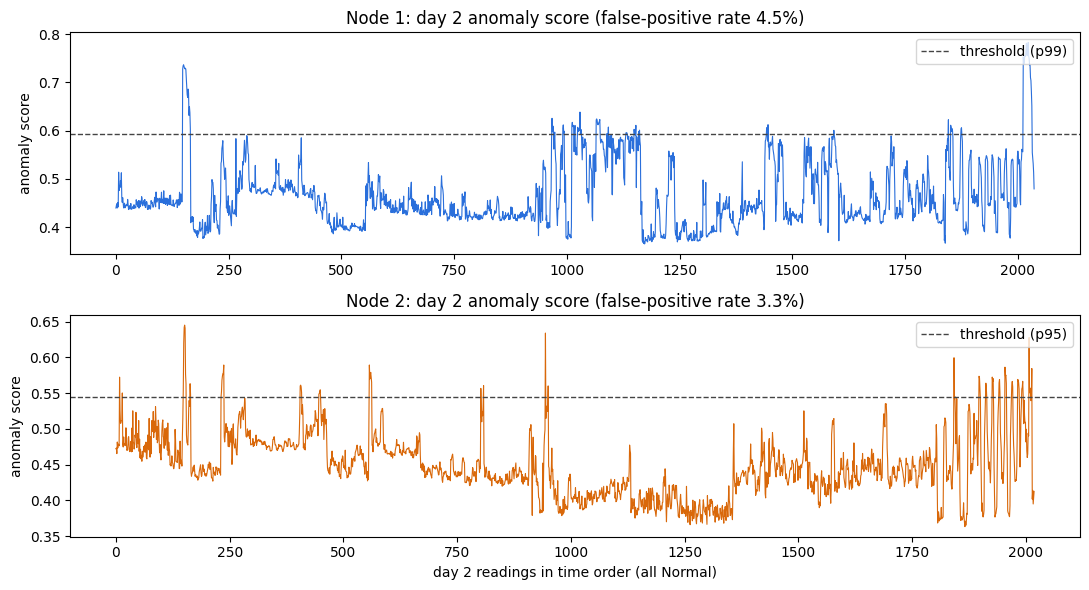

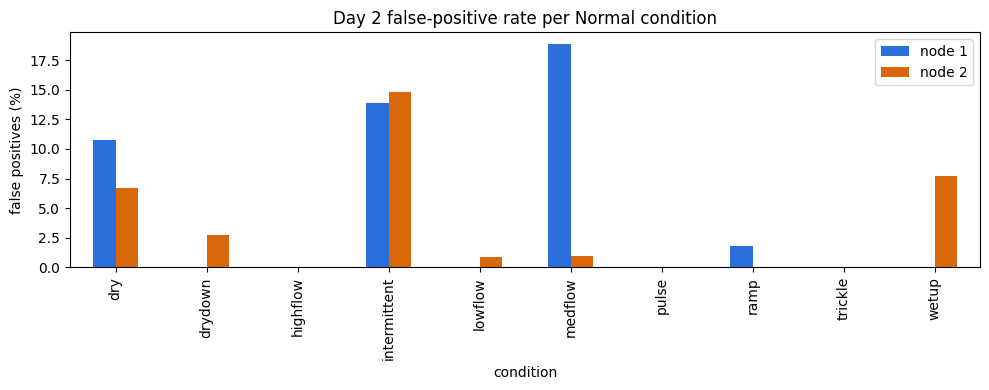

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import matplotlib.pyplot as plt

pcts = {1: 99, 2: 95}
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
rows = []
for ax, node in zip(axes, (1, 2)):
    train, test, feats = data[node]
    sc = StandardScaler().fit(train[feats])
    m = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(sc.transform(train[feats]))
    thr = np.percentile(-m.score_samples(sc.transform(train[feats])), pcts[node])

    t = test.sort_values("timestamp").copy()
    t["score"] = -m.score_samples(sc.transform(t[feats]))
    t["flag"] = t["score"] > thr

    ax.plot(np.arange(len(t)), t["score"], lw=0.8, color="#2a6fdb" if node == 1 else "#d9680a")
    ax.axhline(thr, color="#444", ls="--", lw=1, label=f"threshold (p{pcts[node]})")
    ax.set_title(f"Node {node}: day 2 anomaly score (false-positive rate {t.flag.mean():.1%})")
    ax.set_ylabel("anomaly score")
    ax.legend(loc="upper right")
    rows.append(t.groupby("condition")["flag"].mean().rename(f"node {node}"))
axes[-1].set_xlabel("day 2 readings in time order (all Normal)")
plt.tight_layout()
plt.savefig("fig_if_day2_scores.png", dpi=200)
plt.show()

fp = pd.concat(rows, axis=1).fillna(0) * 100
ax = fp.plot.bar(figsize=(10, 4), color=["#2a6fdb", "#d9680a"])
ax.set_ylabel("false positives (%)")
ax.set_title("Day 2 false-positive rate per Normal condition")
plt.tight_layout()
plt.savefig("fig_if_fpr_by_condition.png", dpi=200)
plt.show()

from google.colab import files
files.download("fig_if_day2_scores.png")
files.download("fig_if_fpr_by_condition.png")

2-minute checks: are the false alarms at segment edges?

In [13]:
EDGE = 21   # 21 readings ≈ 3 minutes
out = []
for node in (1, 2):
    train, test, feats = data[node]
    sc = StandardScaler().fit(train[feats])
    m = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(sc.transform(train[feats]))
    thr = np.percentile(-m.score_samples(sc.transform(train[feats])), pcts[node])

    t = test.sort_values("timestamp").copy()
    t["flag"] = -m.score_samples(sc.transform(t[feats])) > thr
    pos = t.groupby("trial_id").cumcount()
    n = t.groupby("trial_id")["trial_id"].transform("size")
    t["edge"] = (pos < EDGE) | (pos >= n - EDGE)

    out.append(pd.DataFrame({
        "flags_total": [int(t.flag.sum())],
        "flags_at_edges": [int((t.flag & t.edge).sum())],
        "FPR_edges_%": [round(100 * t.loc[t.edge, "flag"].mean(), 1)],
        "FPR_interior_%": [round(100 * t.loc[~t.edge, "flag"].mean(), 1)],
    }, index=[f"node {node}"]))
print(pd.concat(out))

        flags_total  flags_at_edges  FPR_edges_%  FPR_interior_%
node 1           91              46         11.0             2.8
node 2           67              23          5.5             2.8
